# 02 · Imagery coverage and crash matching

**Question:** Where do roads have pre-2023 imagery, and where can we confidently assign 2023–2025 non-intersection crashes to roads?

Run **[01 · Raw data preprocessing](01_raw_data_preprocessing.ipynb)** first, then run this notebook from top to bottom. All analysis and map code is here; no project Python package is imported. It reads the newly prepared cache under `data/processed/` and saves figures to `figures/`. It makes no network requests; notebook 01 handles acquisition.

**Reading the maps:** circle **area** represents a count; circle **color** represents a percentage. Municipality boundaries and road lines provide an offline geographic reference. These are descriptive maps, not maps of risk per vehicle. Tables are limited to compact summaries; full per-record outputs stay in the cache.

**Study status:** matching is automated and provisional. No prediction model, final train/test split, or final crash labels are created here.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown, SVG
from shapely.geometry import box
import shapely

ROOT = Path.cwd()
if not (ROOT / "01_raw_data_preprocessing.ipynb").exists():
    raise RuntimeError("Open this notebook from the project root containing both notebooks.")
RAW = ROOT / "data" / "raw"
CACHE = ROOT / "data" / "processed"
RAW.mkdir(parents=True, exist_ok=True)
FIGURES = ROOT / "figures"
CACHE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
TEAL, ORANGE, GRAY = "#167d8d", "#d66b36", "#c6cdd1"

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

def flowchart(labels, name):
    # Small SVG flowcharts render in saved notebook outputs without extensions.
    from html import escape
    from textwrap import wrap
    width = 250 * len(labels)
    content = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} 95" role="img" aria-label="{escape(" then ".join(labels))}">']
    for i, label in enumerate(labels):
        x = 250 * i + 5
        content.append(f'<rect x="{x}" y="15" width="215" height="60" rx="10" fill="#e9f3f3" stroke="#167d8d"/>')
        lines = [line for part in label.split("|") for line in wrap(part, width=26)]
        for j, line in enumerate(lines):
            content.append(f'<text x="{x+107}" y="{50 - 9*(len(lines)-1) + j*18}" text-anchor="middle" font-family="sans-serif" font-size="14">{escape(line)}</text>')
        if i < len(labels) - 1:
            content.append(f'<path d="M{x+220} 45 h20 m-7 -5 l7 5 -7 5" fill="none" stroke="#167d8d" stroke-width="2"/>')
    content.append('</svg>')
    svg = "".join(content)
    (FIGURES / f"{name}.svg").write_text(svg)
    display(SVG(svg))

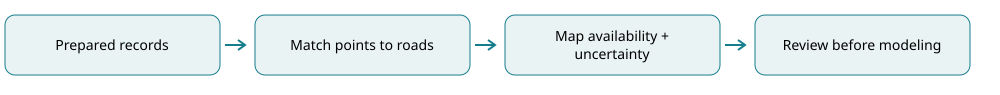

**54,647 study roads · 1,173,713 eligible image records · 22,202 crashes passing preparation checks.**

In [2]:
required = ["preprocessing_metadata.json", "study_municipalities.parquet", "roads.parquet",
            "road_candidates.parquet", "crashes.parquet", "images.parquet", "image_collection_tiles.parquet"]
if any(not (CACHE / name).exists() for name in required):
    raise RuntimeError("Run notebook 01 completely before this notebook.")
settings = json.loads((CACHE / "preprocessing_metadata.json").read_text())
CRS = settings["crs"]
SEARCH_M = settings["candidate_radius_m"]
frame = gpd.read_parquet(CACHE / "study_municipalities.parquet")
roads = gpd.read_parquet(CACHE / "roads.parquet")
roads = roads.loc[roads.eligible].copy().reset_index(drop=True)
candidates = gpd.read_parquet(CACHE / "road_candidates.parquet")
all_crashes = gpd.read_parquet(CACHE / "crashes.parquet")
crashes = all_crashes.loc[all_crashes.crash_status.eq("eligible_for_matching")].copy().reset_index(drop=True)
images = gpd.read_parquet(CACHE / "images.parquet")
images = images.loc[images.image_status.eq("eligible")].copy().reset_index(drop=True)
tiles = gpd.read_parquet(CACHE / "image_collection_tiles.parquet")
assert roads.segment_id.is_unique and candidates.segment_id.is_unique
assert crashes.record_id.is_unique and images.record_id.is_unique
assert all(f.crs == CRS for f in [frame, roads, candidates, crashes, images, tiles])
flowchart(["Prepared records", "Match points to roads", "Map availability + uncertainty", "Review before modeling"], "02_analysis_pipeline")
display(Markdown(f"**{len(roads):,} study roads · {len(images):,} eligible image records · "
                 f"{len(crashes):,} crashes passing preparation checks.**"))

## 1. Match points to roads with explicit rules

We search for all road lines within **50 m** of each point. At the main setting, accept the nearest road only if it is within **20 m** and any runner-up within the search radius is **more than 5 m farther away**. No runner-up means no competing road was found within 50 m; it does not measure an infinite separation.

Crashes must also have matching normalized road names. We standardize abbreviations and remove the structured ` Rte ...` suffix; we do not guess route aliases or switch to a farther road just because its name agrees. Images have no road-name check.

The same functions below handle both sources. Candidate generation uses a spatial index and distances to the **full road line**, not just its midpoint. Images are processed in batches to bound memory use.

In [3]:
MAIN_M = 20.0  # Maximum accepted point-to-road distance at the main setting, in meters.
GAP_M = 5.0  # Second-nearest road must be more than this much farther away, in meters.
DISTANCES = [10.0, 20.0, 30.0]  # Alternative maximum matching distances to compare, in meters.

import re
SUFFIX = {"STREET":"ST", "AVENUE":"AVE", "AV":"AVE", "ROAD":"RD", "BOULEVARD":"BLVD",
          "DRIVE":"DR", "LANE":"LN", "PLACE":"PL", "COURT":"CT", "PARKWAY":"PKWY",
          "HIGHWAY":"HWY", "TERRACE":"TER"}
def normalize_name(value):
    if pd.isna(value): return ""
    street = re.split(r"\s+RTE(?:\s|$)", str(value).upper(), maxsplit=1)[0]
    tokens = re.sub(r"[^A-Z0-9 ]", " ", street).split()
    return " ".join(SUFFIX.get(token, token) for token in tokens)

road_names = candidates.road_name.map(normalize_name)
road_index = candidates.sindex

def candidate_pairs(points):
    pi, ri = road_index.query(points.geometry, predicate="dwithin", distance=SEARCH_M)
    pair = pd.DataFrame({"record_id": points.record_id.to_numpy()[pi],
                         "segment_id": candidates.segment_id.to_numpy()[ri],
                         "distance_m": points.geometry.iloc[pi].reset_index(drop=True).distance(
                             candidates.geometry.iloc[ri].reset_index(drop=True)).to_numpy()})
    pair["name_agreement"] = "missing"
    if "road_name" in points:
        source = points.road_name.map(normalize_name).to_numpy()[pi]
        target = road_names.to_numpy()[ri]
        pair["name_agreement"] = np.select([(source == "") | (target == ""), source == target],
                                           ["missing", "agree"], default="conflict")
    pair = pair.sort_values(["record_id", "distance_m", "segment_id"]).reset_index(drop=True)
    pair["candidate_rank"] = pair.groupby("record_id").cumcount() + 1
    return pair

def assign_roads(points, pairs, threshold, require_name=False):
    first = pairs.loc[pairs.candidate_rank.eq(1)].set_index("record_id")
    second = pairs.loc[pairs.candidate_rank.eq(2)].set_index("record_id")
    result = points[["record_id"]].copy().reset_index(drop=True)
    result["candidate_segment_id"] = result.record_id.map(first.segment_id)
    result["nearest_m"] = result.record_id.map(first.distance_m)
    result["runner_up_m"] = result.record_id.map(second.distance_m)
    result["gap_m"] = result.runner_up_m - result.nearest_m
    result["name_agreement"] = result.record_id.map(first.name_agreement).fillna("missing")
    result["status"] = np.select(
        [result.nearest_m.isna(), result.nearest_m.gt(threshold),
         result.runner_up_m.notna() & result.gap_m.le(GAP_M),
         require_name & result.name_agreement.eq("missing"),
         require_name & result.name_agreement.eq("conflict")],
        ["no_candidate_within_search", "too_far", "ambiguous", "missing_road_name", "road_name_conflict"],
        default="accepted")
    result["segment_id"] = result.candidate_segment_id.where(result.status.eq("accepted"))
    return result

## 2. Imagery availability: first establish the denominator

**Fully assessed** means the entire road's image-search neighborhood lies inside completed collection tiles. **Has imagery** means at least one eligible image has an accepted match to that road. These are different conditions.

For each distance setting, we count only fully assessed study roads in the availability denominator. Accepted image counts across all candidate roads also include outside-study matches and must not be used as a study-road count. The representative metadata record is the latest accepted image, with distance and ID breaking ties; that does not establish photo usability.

In [4]:
image_status_parts, image_road_parts, representatives, main_image_parts = [], [], [], []
BATCH_SIZE = 50000
for start in range(0, len(images), BATCH_SIZE):
    batch = images.iloc[start:start+BATCH_SIZE].reset_index(drop=True)
    pairs = candidate_pairs(batch)
    for threshold in DISTANCES:
        decision = assign_roads(batch, pairs, threshold)
        counts = decision.status.value_counts().rename_axis("status").reset_index(name="records")
        counts["distance_m"] = threshold
        image_status_parts.append(counts)
        accepted = decision.loc[decision.status.eq("accepted")]
        per_road = accepted.groupby("segment_id").size().rename("images").reset_index()
        per_road["distance_m"] = threshold
        image_road_parts.append(per_road)
        if threshold == MAIN_M:
            main_image_parts.append(decision)
            rep = accepted.merge(batch[["record_id", "captured_at_utc"]], on="record_id", validate="one_to_one")
            rep = rep.sort_values(["captured_at_utc", "nearest_m", "record_id"], ascending=[False, True, True])
            representatives.append(rep.drop_duplicates("segment_id"))
image_status = pd.concat(image_status_parts).groupby(["distance_m", "status"], as_index=False).records.sum()
image_road_counts = pd.concat(image_road_parts).groupby(["distance_m", "segment_id"], as_index=False).images.sum()
image_decisions = pd.concat(main_image_parts, ignore_index=True)
image_decisions.to_parquet(CACHE / "image_match_decisions.parquet", index=False)
representative = pd.concat(representatives).sort_values(["captured_at_utc", "nearest_m", "record_id"], ascending=[False, True, True]).drop_duplicates("segment_id")
representative.loc[representative.segment_id.isin(roads.segment_id)].to_parquet(CACHE / "representative_study_images.parquet", index=False)
completed = tiles.loc[tiles.status.eq("complete")].geometry.union_all()
availability_rows = []
for threshold in DISTANCES:
    assessed = roads.geometry.buffer(threshold).difference(completed).area.le(0.001)
    matched_ids = image_road_counts.loc[image_road_counts.distance_m.eq(threshold), "segment_id"]
    has_image = roads.segment_id.isin(matched_ids)
    n_assessed, n_covered = int(assessed.sum()), int((assessed & has_image).sum())
    availability_rows.append({"Distance (m)": threshold, "Fully assessed roads": n_assessed,
                              "Roads with imagery": n_covered,
                              "Imagery share (%)": 100*n_covered/n_assessed if n_assessed else np.nan})
    if threshold == MAIN_M:
        roads["fully_assessed"] = assessed
        roads["has_image"] = has_image
        main_counts = image_road_counts.loc[image_road_counts.distance_m.eq(threshold)].set_index("segment_id").images
        roads["matched_images"] = roads.segment_id.map(main_counts).fillna(0).astype(int)
availability = pd.DataFrame(availability_rows)
roads.to_parquet(CACHE / "image_coverage.parquet")
image_status.to_parquet(CACHE / "image_matching_summary.parquet", index=False)
N = int(roads.fully_assessed.sum())
C = int((roads.fully_assessed & roads.has_image).sum())
display(Markdown(f"**{N:,}/{len(roads):,} roads fully assessed; {C:,}/{N:,} ({100*C/N:.1f}%) have matched imagery.** "
                 f"That leaves {N-C:,} assessed roads without accepted imagery at {MAIN_M:g} m. "
                 "No accepted match is not proof that no photograph exists."))
del main_image_parts, representatives, image_status_parts, image_road_parts, pairs, decision, batch

**54,647/54,647 roads fully assessed; 14,004/54,647 (25.6%) have matched imagery.** That leaves 40,643 assessed roads without accepted imagery at 20 m. No accepted match is not proof that no photograph exists.

### Where is imagery available?

The first map shows the overall geographic pattern. **Circle area = number of assessed roads with imagery; color = percentage of assessed roads with imagery.** Circles sit at representative points within municipalities, not at image capture locations. The second map shows the actual study road lines with and without imagery.

All maps use projected meters, equal spatial aspect, a north arrow, and a scale bar. Municipality boundaries provide context without requiring an internet basemap.

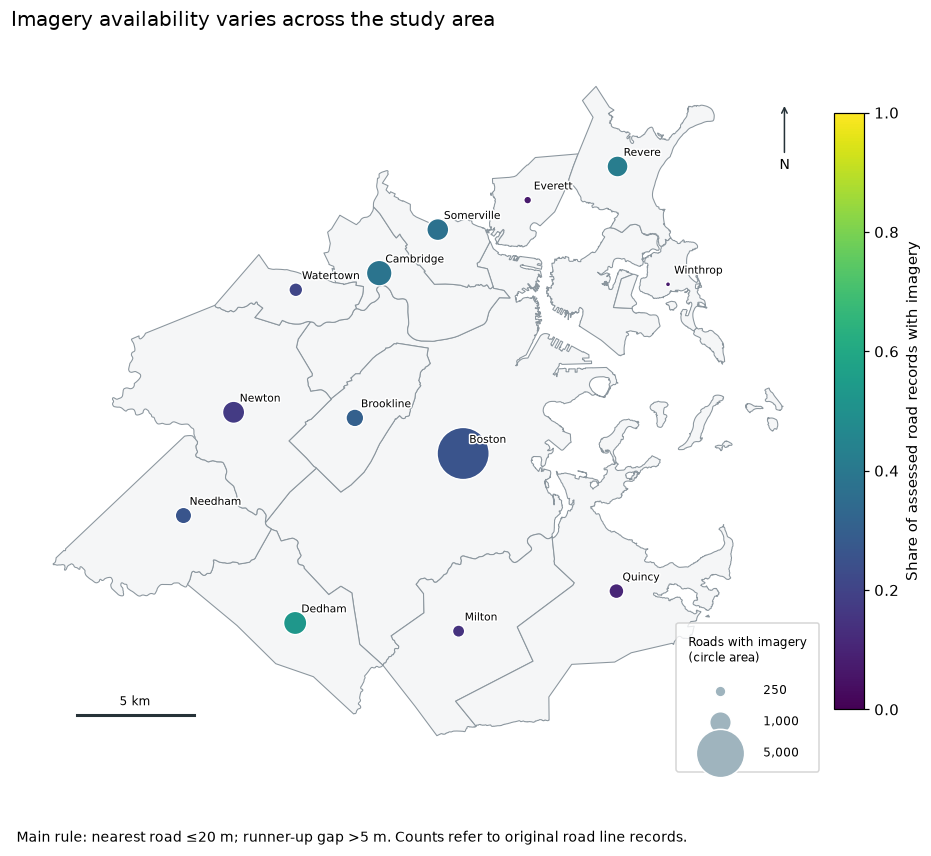

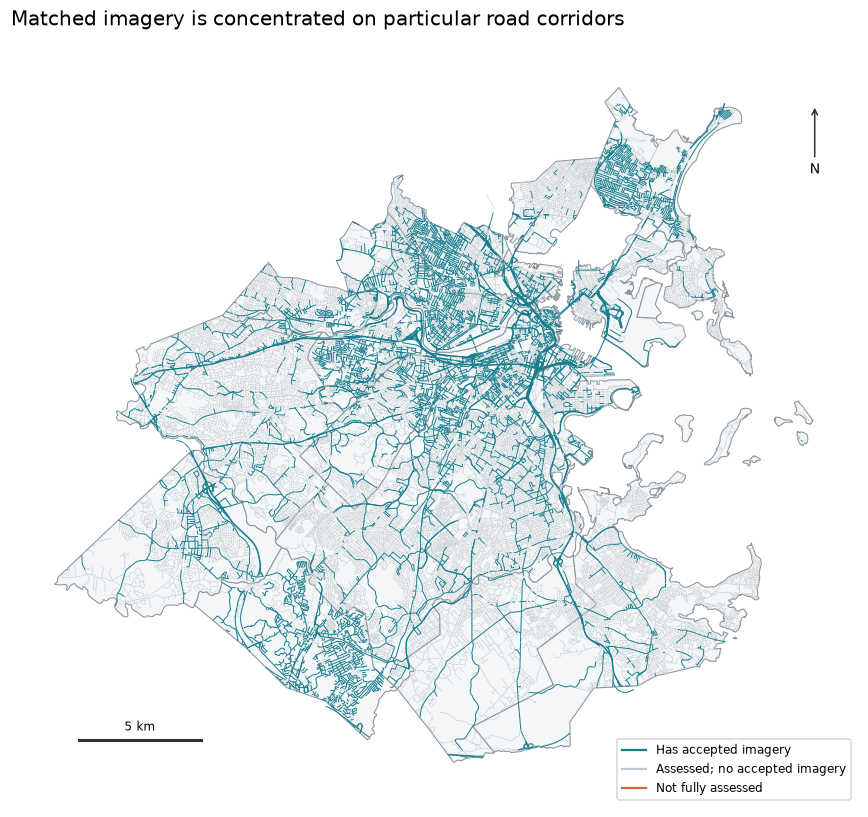

**Finding:** Dedham has the highest observed imagery share (53.0%); Winthrop the lowest (7.1%). The map describes uneven availability; it does not explain its cause.

In [5]:
from matplotlib import colors, patheffects

def base_map(ax, title, labels=False):
    frame.plot(ax=ax, facecolor="#f5f6f7", edgecolor="#8b969e", linewidth=0.7, zorder=0)
    xmin, ymin, xmax, ymax = frame.total_bounds
    ax.set_xlim(xmin-1800, xmax+1800)
    ax.set_ylim(ymin-1800, ymax+1800)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, loc="left", fontsize=13, pad=12)
    x, y = xmin+1000, ymin+900
    ax.plot([x, x+5000], [y, y], color="#263238", lw=2)
    ax.text(x+2500, y+400, "5 km", ha="center", fontsize=8)
    ax.annotate("N", xy=(0.95, 0.92), xytext=(0.95, 0.83), xycoords="axes fraction",
                ha="center", arrowprops={"arrowstyle":"->", "color":"#263238"}, fontsize=9)
    if labels:
        for _, row in frame.iterrows():
            p = row.geometry.representative_point()
            text = ax.annotate(row.municipality.title(), (p.x, p.y), xytext=(4, 7),
                               textcoords="offset points", fontsize=7, zorder=5)
            text.set_path_effects([patheffects.withStroke(linewidth=2, foreground="white")])

def size_legend(ax, values, scale, title):
    handles = [ax.scatter([], [], s=value/scale, facecolor="#9fb4be", edgecolor="white", label=f"{value:,}") for value in values]
    ax.legend(handles=handles, title=title, loc="lower right", frameon=True, fontsize=8,
              title_fontsize=8, labelspacing=1.5, borderpad=1,
              handlelength=4, handletextpad=1.5)

municipal = roads.groupby("municipality").agg(
    study_roads=("segment_id", "size"), assessed=("fully_assessed", "sum"))
covered = roads.loc[roads.fully_assessed & roads.has_image].groupby("municipality").size()
municipal["with_image"] = covered.reindex(municipal.index, fill_value=0)
municipal["share"] = municipal.with_image.div(municipal.assessed.replace(0, np.nan))
municipal_map = frame.merge(municipal, left_on="municipality", right_index=True, validate="one_to_one")
centers = municipal_map.geometry.representative_point()
fig, ax = plt.subplots(figsize=(10, 9))
base_map(ax, "Imagery availability varies across the study area", labels=True)
sc = ax.scatter(centers.x, centers.y, s=municipal_map.with_image/5, c=municipal_map.share,
                cmap="viridis", vmin=0, vmax=1, edgecolors="white", linewidths=0.9, zorder=3)
fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.01, label="Share of assessed road records with imagery")
size_legend(ax, [250, 1000, 5000], 5, "Roads with imagery\n(circle area)")
fig.text(0.13, 0.06, "Main rule: nearest road ≤20 m; runner-up gap >5 m. Counts refer to original road line records.", fontsize=9)
save_figure(fig, "02_imagery_municipality_map")

fig, ax = plt.subplots(figsize=(10, 9))
base_map(ax, "Matched imagery is concentrated on particular road corridors")
roads.loc[roads.fully_assessed & ~roads.has_image].plot(ax=ax, color="#c4cbd0", linewidth=0.35, zorder=1)
roads.loc[roads.fully_assessed & roads.has_image].plot(ax=ax, color=TEAL, linewidth=0.65, zorder=2)
unassessed = roads.loc[~roads.fully_assessed]
if len(unassessed): unassessed.plot(ax=ax, color=ORANGE, linewidth=0.6)
ax.legend(handles=[Line2D([0],[0], color=TEAL, label="Has accepted imagery"),
                   Line2D([0],[0], color="#c4cbd0", label="Assessed; no accepted imagery"),
                   Line2D([0],[0], color=ORANGE, label="Not fully assessed")],
          loc="lower right", fontsize=8)
save_figure(fig, "02_imagery_road_map")
ranked = municipal.sort_values("share")
low, high = ranked.index[0], ranked.index[-1]
display(Markdown(f"**Finding:** {high.title()} has the highest observed imagery share "
                 f"({ranked.loc[high, 'share']:.1%}); {low.title()} the lowest ({ranked.loc[low, 'share']:.1%}). "
                 "The map describes uneven availability; it does not explain its cause."))

### Are photographed roads representative?

Compare road classes using percentages rather than a large municipality-by-class table. Also inspect image age: keeping capture dates before the crash period avoids future imagery, but older photos may show conditions that have changed.

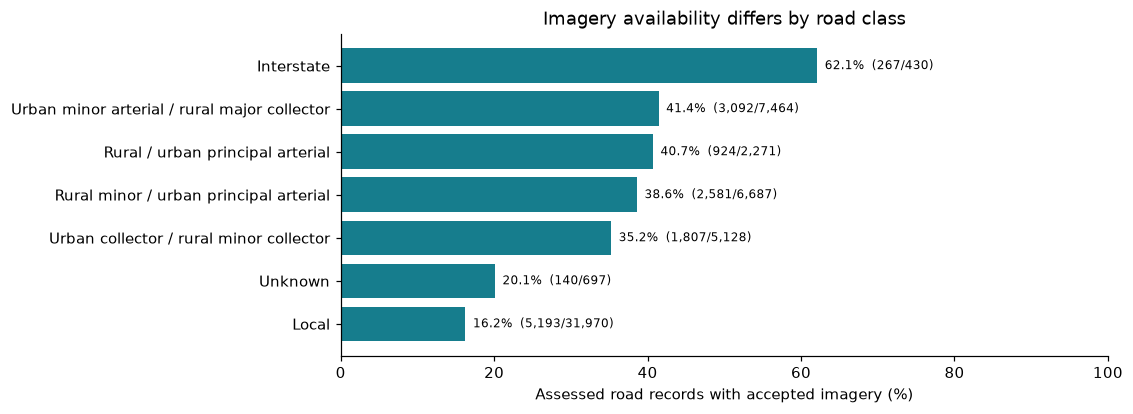

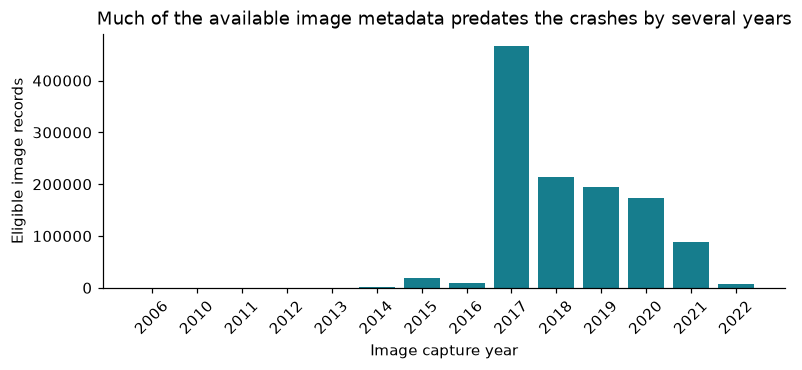

**Finding:** median available AADT is 6,956 on roads with imagery versus 1,154 without imagery. This is descriptive: AADT is missing on some roads and many reference years are unknown. Any future imagery model represents a selected subset of the road network; compare models on identical roads.

In [6]:
class_counts = roads.loc[roads.fully_assessed].groupby("road_class").has_image.agg(["size", "sum"])
class_counts["share"] = class_counts["sum"] / class_counts["size"]
class_counts = class_counts.sort_values("share")
short_labels = {"Rural minor arterial or urban principal arterial":"Rural minor / urban principal arterial",
                "Rural or urban principal arterial":"Rural / urban principal arterial",
                "Urban collector or rural minor collector":"Urban collector / rural minor collector",
                "Urban minor arterial or rural major collector":"Urban minor arterial / rural major collector"}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh([short_labels.get(s,s) for s in class_counts.index], class_counts.share*100, color=TEAL)
ax.set(xlim=(0,100), xlabel="Assessed road records with accepted imagery (%)", title="Imagery availability differs by road class")
for i, (_, r) in enumerate(class_counts.iterrows()):
    ax.text(r.share*100+1, i, f"{r.share:.1%}  ({int(r['sum']):,}/{int(r['size']):,})", va="center", fontsize=8)
save_figure(fig, "02_imagery_by_road_class")
by_year = images.captured_at_utc.dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(by_year.index.astype(str), by_year.values, color=TEAL)
ax.set(xlabel="Image capture year", ylabel="Eligible image records", title="Much of the available image metadata predates the crashes by several years")
ax.tick_params(axis="x", rotation=45)
save_figure(fig, "02_image_capture_years")
medians = roads.groupby("has_image").aadt.median()
display(Markdown(f"**Finding:** median available AADT is {medians.get(True, float('nan')):,.0f} on roads with imagery "
                 f"versus {medians.get(False, float('nan')):,.0f} without imagery. "
                 "This is descriptive: AADT is missing on some roads and many reference years are unknown. "
                 "Any future imagery model represents a selected subset of the road network; compare models on identical roads."))

## 3. Crash matching: what gets accepted?

Only `crash_status == "eligible_for_matching"` enters this calculation. Missing geometry, intersections, unknown junction types, duplicate event IDs, and other preparation failures remain counted in notebook 01. Here, a matching **status** describes what happened after those checks.

A small distance alone is insufficient: parallel lines, divided roads, and junction approaches can have several close candidates. The first failed matching check determines the status; a record can have additional underlying issues.

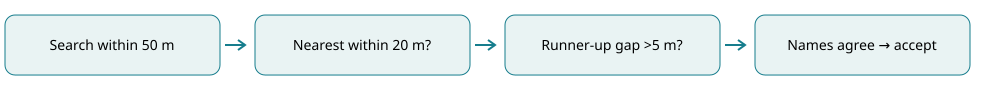

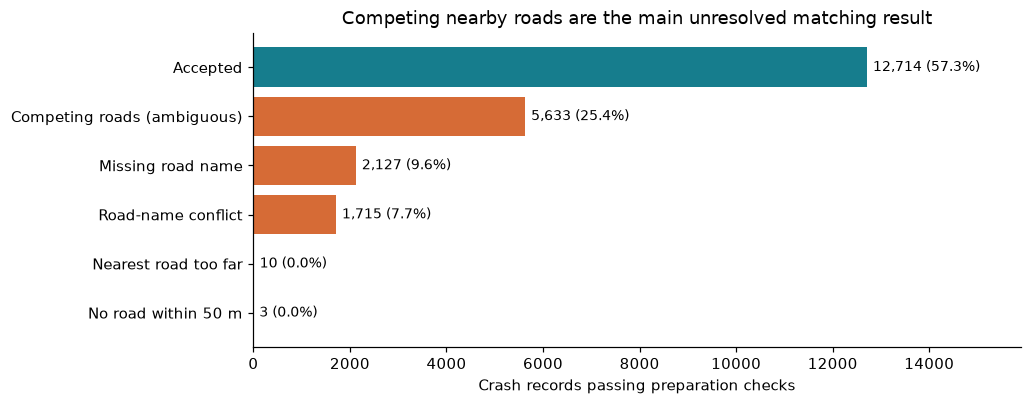

**12,714/22,202 (57.3%) accepted; 5,633 ambiguous.** Accepted matches can be to outside-study candidate roads; this is not a final-cohort crash count. Accepted means the automated checks passed, not that a human verified the assignment.

In [7]:
flowchart(["Search within 50 m", "Nearest within 20 m?", "Runner-up gap >5 m?", "Names agree → accept"], "02_crash_matching_rules")
crash_pairs = candidate_pairs(crashes)
crash_conditions = []
for threshold in DISTANCES:
    decision = assign_roads(crashes, crash_pairs, threshold, require_name=True)
    decision["distance_m"] = threshold
    crash_conditions.append(decision)
crash_decisions = pd.concat(crash_conditions, ignore_index=True)
crash_decisions.to_parquet(CACHE / "crash_match_decisions.parquet", index=False)
crash_pairs.to_parquet(CACHE / "crash_candidate_pairs.parquet", index=False)
main = crash_decisions.loc[crash_decisions.distance_m.eq(MAIN_M)].copy()
status = main.status.value_counts()
status_labels = {"accepted":"Accepted", "ambiguous":"Competing roads (ambiguous)",
                 "missing_road_name":"Missing road name", "road_name_conflict":"Road-name conflict",
                 "too_far":"Nearest road too far", "no_candidate_within_search":"No road within 50 m"}
fig, ax = plt.subplots(figsize=(9, 3.7))
plot_counts = status.rename(index=status_labels).sort_values()
ax.barh(plot_counts.index, plot_counts.values, color=[TEAL if s=="Accepted" else ORANGE for s in plot_counts.index])
for i, (label, value) in enumerate(plot_counts.items()):
    ax.text(value+120, i, f"{value:,} ({value/len(main):.1%})", va="center", fontsize=9)
ax.set(xlim=(0, plot_counts.max()*1.25), xlabel="Crash records passing preparation checks", title="Competing nearby roads are the main unresolved matching result")
save_figure(fig, "02_crash_matching_status")
display(Markdown(f"**{status.get('accepted',0):,}/{len(main):,} ({status.get('accepted',0)/len(main):.1%}) accepted; "
                 f"{status.get('ambiguous',0):,} ambiguous.** "
                 "Accepted matches can be to outside-study candidate roads; this is not a final-cohort crash count. "
                 "Accepted means the automated checks passed, not that a human verified the assignment."))

### Where are crash matches uncertain?

Aggregate screened crash points into fixed **1 km × 1 km cells**. A circle is placed at each cell center, so it is an area summary, not a precise crash location.

Both maps use **circle area = number of screened crashes in the cell**. On the left, color shows the percentage with accepted matches; on the right, the percentage classified as ambiguous. Blank cells have no screened crashes, not necessarily no crashes. Percentages in small circles are based on few records and are less stable.

All years are pooled. The grid includes only crashes passing preparation, so it does not show the spatial distribution of excluded or ungeocoded crashes. These maps cannot establish that one area is more dangerous.

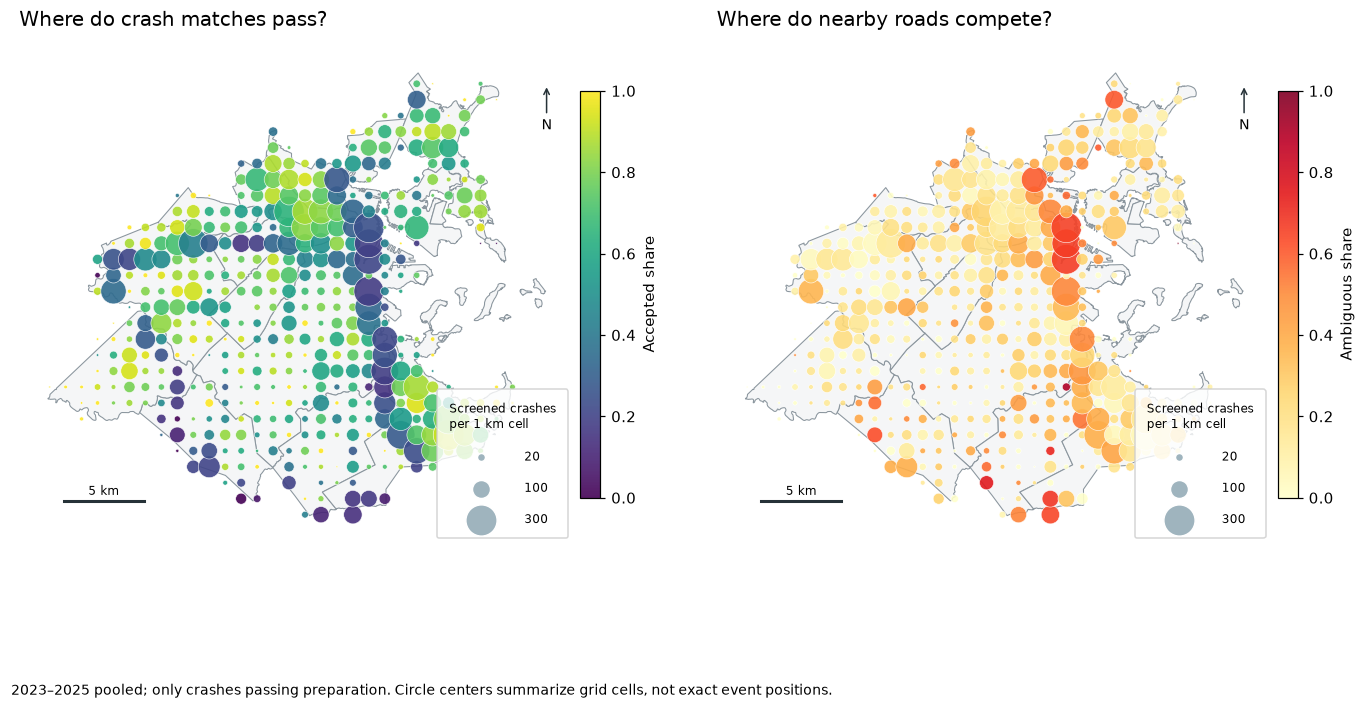

In [8]:
crash_map = crashes.merge(main[["record_id", "status"]], on="record_id", validate="one_to_one")
crash_map["grid_x"] = np.floor(crash_map.geometry.x/1000).astype(int)
crash_map["grid_y"] = np.floor(crash_map.geometry.y/1000).astype(int)
crash_map["accepted"] = crash_map.status.eq("accepted")
crash_map["ambiguous"] = crash_map.status.eq("ambiguous")
grid = crash_map.groupby(["grid_x", "grid_y"]).agg(
    records=("record_id", "size"), accepted_share=("accepted", "mean"), ambiguous_share=("ambiguous", "mean")).reset_index()
grid = gpd.GeoDataFrame(grid, geometry=gpd.points_from_xy(grid.grid_x*1000+500, grid.grid_y*1000+500), crs=CRS)
fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, field, title in zip(axes, ["accepted_share", "ambiguous_share"],
                             ["Where do crash matches pass?", "Where do nearby roads compete?"]):
    base_map(ax, title)
    sc = ax.scatter(grid.geometry.x, grid.geometry.y, s=grid.records*1.4, c=grid[field],
                    cmap="viridis" if field=="accepted_share" else "YlOrRd", vmin=0, vmax=1,
                    edgecolors="#ffffff", linewidths=0.4, alpha=0.9, zorder=2)
    fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.01,
                 label="Accepted share" if field=="accepted_share" else "Ambiguous share")
    size_legend(ax, [20, 100, 300], 1/1.4, "Screened crashes\nper 1 km cell")
fig.text(0.12, 0.04, "2023–2025 pooled; only crashes passing preparation. Circle centers summarize grid cells, not exact event positions.", fontsize=9)
save_figure(fig, "02_crash_matching_grid_maps")

### A local example: why a nearby point can remain unresolved

For illustration, choose the 1 km cell with the most ambiguous matches and zoom to a 1.5 km neighborhood. This reproducible choice explains the rule; it does **not** change the study area or any future test split. Background lines include nearby outside-study candidate roads.

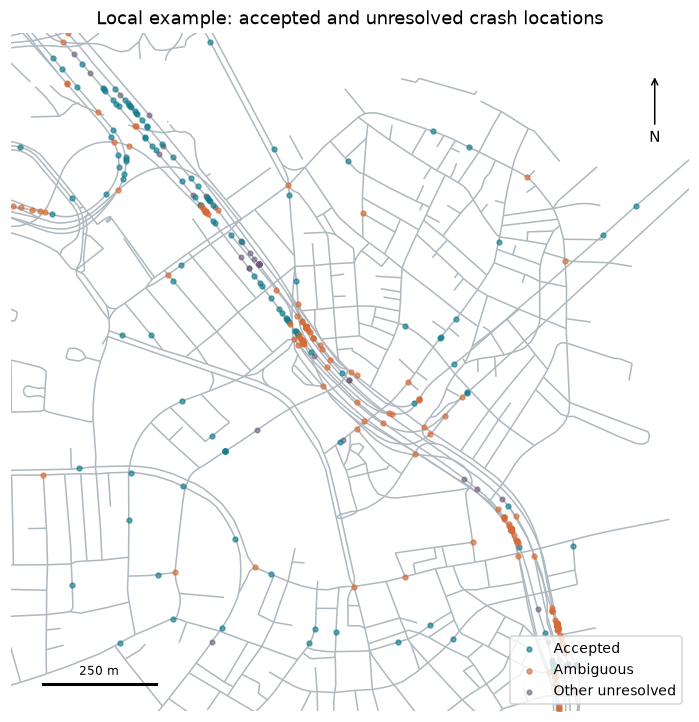

**Read this as a diagnostic example.** Overlapping points can hide repeated locations; the grid map above preserves counts. A point touching a line is not independent proof of accurate source geocoding.

In [9]:
ambiguous_cells = crash_map.loc[crash_map.ambiguous].groupby(["grid_x", "grid_y"]).size()
if len(ambiguous_cells):
    gx, gy = ambiguous_cells.idxmax()
else:
    gx, gy = crash_map.groupby(["grid_x", "grid_y"]).size().idxmax()
x0, y0 = gx*1000-250, gy*1000-250
window = box(x0, y0, x0+1500, y0+1500)
local_roads = candidates.loc[candidates.geometry.intersects(window)]
local_points = crash_map.loc[crash_map.geometry.intersects(window)]
fig, ax = plt.subplots(figsize=(9, 8))
local_roads.plot(ax=ax, color="#aeb8bf", linewidth=1, zorder=1)
for flag, color, label in [(False, TEAL, "Accepted"), (True, ORANGE, "Ambiguous")]:
    points = local_points.loc[local_points.status.eq("ambiguous" if flag else "accepted")]
    if len(points): ax.scatter(points.geometry.x, points.geometry.y, s=10, c=color, alpha=0.65, label=label, zorder=3)
other = local_points.loc[~local_points.status.isin(["accepted", "ambiguous"])]
if len(other): ax.scatter(other.geometry.x, other.geometry.y, s=9, c="#6c5b7b", alpha=0.6, label="Other unresolved", zorder=2)
ax.set(xlim=(x0,x0+1500), ylim=(y0,y0+1500), aspect="equal",
       title="Local example: accepted and unresolved crash locations")
ax.set_axis_off()
ax.plot([x0+70, x0+320], [y0+60, y0+60], color="black", lw=2)
ax.text(x0+195, y0+80, "250 m", ha="center", fontsize=8)
ax.annotate("N", xy=(0.95,0.94), xytext=(0.95,0.84), xycoords="axes fraction", ha="center", arrowprops={"arrowstyle":"->"})
ax.legend(loc="lower right", fontsize=9)
save_figure(fig, "02_crash_local_example")
display(Markdown("**Read this as a diagnostic example.** Overlapping points can hide repeated locations; "
                 "the grid map above preserves counts. A point touching a line is not independent proof of accurate source geocoding."))

## 4. Do distance settings change the findings?

Compare 10, 20, and 30 m while keeping the search radius at 50 m and runner-up margin at 5 m. This three-row table is the only distance-comparison table needed. Stable counts indicate limited sensitivity to this setting, not proven matching accuracy.

In [10]:
accepted_by_distance = crash_decisions.loc[crash_decisions.status.eq("accepted")].groupby("distance_m").size()
comparison = availability.copy()
comparison["Accepted crash matches"] = comparison["Distance (m)"].map(accepted_by_distance).fillna(0).astype(int)
display(comparison.style.format({"Distance (m)":"{:.0f}", "Fully assessed roads":"{:,.0f}",
                                "Roads with imagery":"{:,.0f}", "Imagery share (%)":"{:.2f}", "Accepted crash matches":"{:,.0f}"}).hide(axis="index"))
change = int(accepted_by_distance.get(max(DISTANCES),0)-accepted_by_distance.get(min(DISTANCES),0))
image_change = int(comparison.iloc[-1]["Roads with imagery"]-comparison.iloc[0]["Roads with imagery"])
display(Markdown(f"**Finding:** moving from {min(DISTANCES):g} m to {max(DISTANCES):g} m adds "
                 f"{change:,} accepted crash matches and {image_change:,} roads with imagery. "
                 "Within these tested distances, competing roads and name problems matter more than distance rejection."))

Distance (m),Fully assessed roads,Roads with imagery,Imagery share (%),Accepted crash matches
10,"54,647","13,923",25.48,"12,683"
20,"54,647","14,004",25.63,"12,714"
30,"54,647","14,034",25.68,"12,715"


**Finding:** moving from 10 m to 30 m adds 32 accepted crash matches and 111 roads with imagery. Within these tested distances, competing roads and name problems matter more than distance rejection.

## 5. Show how unresolved crashes reduce the comparison road set

An unresolved crash could belong to any of its nearby candidate roads. Treating all those roads as having zero crashes would be misleading. The conservative comparison rule excludes **every study road within 50 m of a crash unresolved under any tested distance setting**, then uses the same remaining road set for all settings.

This is a large restriction, so we map its impact. **Circle area = excluded study-road count; color = fraction of study roads excluded.** Counts refer to road line records, not road length or municipalities removed.

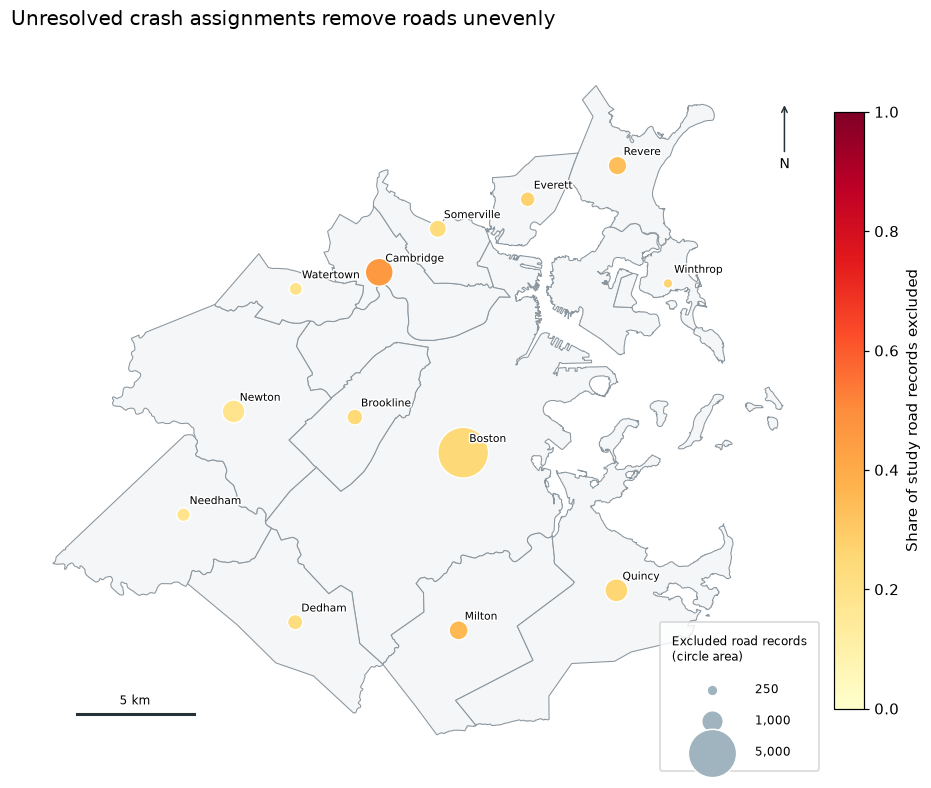

**14,067/54,647 roads (25.7%) are excluded; 40,580 remain in the common comparison set.** This set and the roads with imagery are different sets; neither count is the final photographed cohort size.

In [11]:
unresolved_ids = set(crash_decisions.loc[crash_decisions.status.ne("accepted"), "record_id"])
excluded_ids = set(crash_pairs.loc[crash_pairs.record_id.isin(unresolved_ids), "segment_id"])
roads["excluded_for_uncertainty"] = roads.segment_id.isin(excluded_ids)
roads["in_common_comparison"] = ~roads.excluded_for_uncertainty
roads[["segment_id", "in_common_comparison", "excluded_for_uncertainty"]].to_parquet(CACHE / "comparison_road_flags.parquet", index=False)
impact = roads.groupby("municipality").excluded_for_uncertainty.agg(["size", "sum", "mean"])
impact_map = frame.merge(impact, left_on="municipality", right_index=True)
centers = impact_map.geometry.representative_point()
fig, ax = plt.subplots(figsize=(10, 9))
base_map(ax, "Unresolved crash assignments remove roads unevenly", labels=True)
sc = ax.scatter(centers.x, centers.y, s=impact_map["sum"]/5, c=impact_map["mean"], cmap="YlOrRd",
                vmin=0, vmax=1, edgecolors="white", linewidths=0.9, zorder=3)
fig.colorbar(sc, ax=ax, fraction=0.035, pad=0.01, label="Share of study road records excluded")
size_legend(ax, [250, 1000, 5000], 5, "Excluded road records\n(circle area)")
save_figure(fig, "02_uncertainty_exclusion_map")
excluded = int(roads.excluded_for_uncertainty.sum())
common = int(roads.in_common_comparison.sum())
display(Markdown(f"**{excluded:,}/{len(roads):,} roads ({excluded/len(roads):.1%}) are excluded; "
                 f"{common:,} remain in the common comparison set.** "
                 "This set and the roads with imagery are different sets; neither count is the final photographed cohort size."))

## 6. Findings to present and work still needed

- **Completed searching is different from having imagery.** The main imagery map shows both the available sample and its geographic imbalance.
- **Road class and image age matter.** Photographed roads need not represent all roads, and older images may not show current road conditions.
- **Nearest-road distance alone is insufficient.** Many crashes have competing nearby road lines or name issues; the spatial diagnostics show where this occurs.
- **The uncertainty policy costs sample size.** Report the common comparison exclusions alongside any later model results.

**Before modeling:** review at least 50 crash and 50 image assignments, inspect photograph usability, confirm junction and matching policies, and lock the geographic split without selecting it from crash outcomes. The archived snapshot recorded zero completed manual reviews. This notebook does not update human review decisions or treat automated matches as reviewed labels.

Use the same roads, inventory features, and geographic split when comparing inventory-only and imagery-enhanced models. A road with no accepted crash match is not proven crash-free. The maps show counts and matching uncertainty, not exposure-adjusted danger or causal effects.

**Deliverable:** these two notebooks contain all executable logic; `figures/` holds their charts and diagrams. `data/raw/` stores source downloads and `data/processed/` stores the regenerated data and analysis outputs. Re-running notebook 01 rebuilds preprocessing; re-running this notebook rebuilds matching and maps.

In [12]:
# Small handoff summary; full per-record results remain in the data cache.
summary = pd.DataFrame({"Measure": ["Study roads passing checks", "Fully assessed image-search neighborhoods",
                                    "Roads with imagery (20 m)", "Screened crashes", "Accepted crash matches (20 m)",
                                    "Common comparison roads"],
                        "Count": [len(roads), N, C, len(crashes), int(status.get("accepted",0)), common]})
display(summary.style.format({"Count":"{:,.0f}"}).hide(axis="index"))
assert len(main) == len(crashes)
assert len(image_decisions) == len(images)
assert common + excluded == len(roads)
assert C <= N <= len(roads)
summary.to_json(CACHE / "analysis_summary.json", orient="records", indent=2)

Measure,Count
Study roads passing checks,"54,647"
Fully assessed image-search neighborhoods,"54,647"
Roads with imagery (20 m),"14,004"
Screened crashes,"22,202"
Accepted crash matches (20 m),"12,714"
Common comparison roads,"40,580"
